In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import auc, roc_auc_score, roc_curve

In [39]:
DISEASE  = 'effusion'
CF_COUNT = 16
BASE_DIR = '/zhome/d0/a/221493/thesis/results'
MODEL    = 'LR'
CONFIG   = 'M6'

In [40]:
plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 16,
    'axes.titlesize': 17,
    'axes.labelsize': 16,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 1.2,
    'grid.alpha': 0.3,
})



In [4]:
 # ── Load predictions ──────────────────────────────────────────────────────
cv_dir = os.path.join(BASE_DIR, f'C2_custom/{DISEASE}/cv_results/cf_{CF_COUNT}')
files  = sorted([f for f in os.listdir(cv_dir)
                     if f.startswith("fold_") and f.endswith("_predictions.csv")])

df      = pd.concat([pd.read_csv(os.path.join(cv_dir, f)) for f in files], ignore_index=True)
correct = df["correct"].values
scores  = df[f"{MODEL}_{CONFIG}_prob"].values
base_error   = 1 - correct.mean()

In [41]:
print(df.columns.tolist())

['path', 'effusion_prob', 'effusion_true', 'emb_0', 'emb_1', 'emb_2', 'emb_3', 'emb_4', 'emb_5', 'emb_6', 'emb_7', 'emb_8', 'emb_9', 'emb_10', 'emb_11', 'emb_12', 'emb_13', 'emb_14', 'emb_15', 'emb_16', 'emb_17', 'emb_18', 'emb_19', 'emb_20', 'emb_21', 'emb_22', 'emb_23', 'emb_24', 'emb_25', 'emb_26', 'emb_27', 'emb_28', 'emb_29', 'emb_30', 'emb_31', 'emb_32', 'emb_33', 'emb_34', 'emb_35', 'emb_36', 'emb_37', 'emb_38', 'emb_39', 'emb_40', 'emb_41', 'emb_42', 'emb_43', 'emb_44', 'emb_45', 'emb_46', 'emb_47', 'emb_48', 'emb_49', 'emb_50', 'emb_51', 'emb_52', 'emb_53', 'emb_54', 'emb_55', 'emb_56', 'emb_57', 'emb_58', 'emb_59', 'emb_60', 'emb_61', 'emb_62', 'emb_63', 'emb_64', 'emb_65', 'emb_66', 'emb_67', 'emb_68', 'emb_69', 'emb_70', 'emb_71', 'emb_72', 'emb_73', 'emb_74', 'emb_75', 'emb_76', 'emb_77', 'emb_78', 'emb_79', 'emb_80', 'emb_81', 'emb_82', 'emb_83', 'emb_84', 'emb_85', 'emb_86', 'emb_87', 'emb_88', 'emb_89', 'emb_90', 'emb_91', 'emb_92', 'emb_93', 'emb_94', 'emb_95', 'emb_96

In [42]:
y_true = df["effusion_true"].values
y_pred = df[f"{MODEL}_{CONFIG}_prob"].values
print(f"ROC AUC: {roc_auc_score(y_true, y_pred):.4f}")

ROC AUC: 0.7024


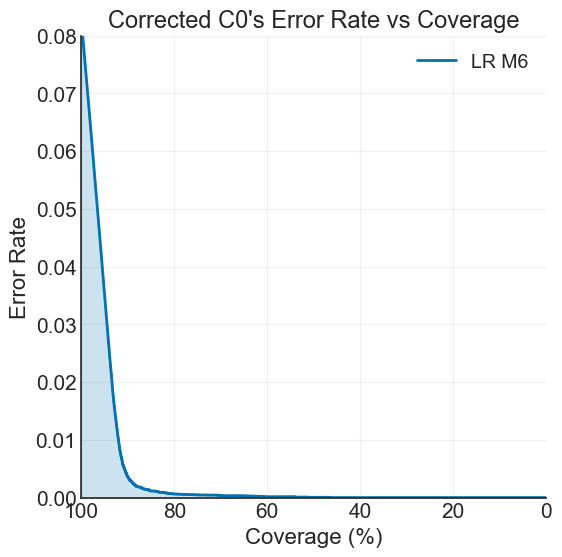

In [43]:
n = len(scores)
order = np.argsort(scores)[::-1] # Sort in descending order
sorted_correct = correct[order]
sorted_scores = scores[order]
cumulative_errors = np.cumsum(1 - sorted_correct)
k = np.arange(1, n + 1)
coverage = k / n * 100
error_rate = cumulative_errors / k
# Flip coverage and error_rate for better visualization
coverage = coverage[::-1]
error_rate = error_rate[::-1]

# plOT WITH COVERAGE GOINF FROM 100 TO 0
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(coverage, error_rate, label=f'{MODEL} {CONFIG}', color='#0072B2', linewidth=2)
# fill area under curve
ax.fill_between(coverage, error_rate, alpha=0.2, color='#0072B2')
ax.set_xlabel('Coverage (%)')
ax.set_ylabel('Error Rate')
ax.set_title(f"Corrected C0's Error Rate vs Coverage")
ax.legend()
ax.set_xlim(100, 0)
ax.set_ylim(0, 0.08)
plt.grid()
plt.show()

In [46]:
y_true = df["effusion_true"].values
y_prob = df["effusion_prob"].values
scores = df[f"{MODEL}_{CONFIG}_prob"].values

# disease classifier prediction
y_pred = (y_prob >= 0.5634).astype(int)

# QC score used for rejection
qc_score = scores

# Old line: thresholds = np.linspace(0, 1, 101)
# New line: This ensures coverage goes perfectly from 100% to 0%
thresholds = np.percentile(qc_score, np.linspace(0, 100, 101))

coverages = []
sensitivities = []
specificities = []

for thr in thresholds:
    accepted = qc_score >= thr
    if accepted.sum() == 0:
        coverages.append(0)
        sensitivities.append(np.nan)
        specificities.append(np.nan)
        continue

    yt = y_true[accepted]
    yp = y_pred[accepted]

    tn = np.sum((yt == 0) & (yp == 0))
    fp = np.sum((yt == 0) & (yp == 1))
    fn = np.sum((yt == 1) & (yp == 0))
    tp = np.sum((yt == 1) & (yp == 1))

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    coverages.append(100 * accepted.mean())
    sensitivities.append(sensitivity)
    specificities.append(specificity)

In [ ]:
print(len(specificities), len(coverages), len(sensitivities))

101 101 101


: 

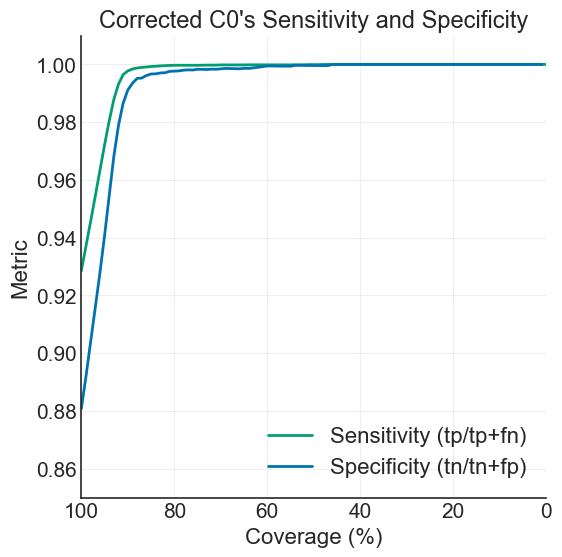

In [47]:
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(coverages, sensitivities, label='Sensitivity (tp/tp+fn)', linewidth=2, color='#009E73')
ax.plot(coverages, specificities, label='Specificity (tn/tn+fp)', linewidth=2, color='#0072B2')

ax.set_xlabel('Coverage (%)')
ax.set_ylabel('Metric')
ax.set_xlim(100, 0)
ax.set_ylim(0.85, 1.01)

ax.legend(loc='lower right', fontsize=16)
# titlke
plt.title(f'Corrected C0\'s Sensitivity and Specificity')
plt.grid()
plt.show()

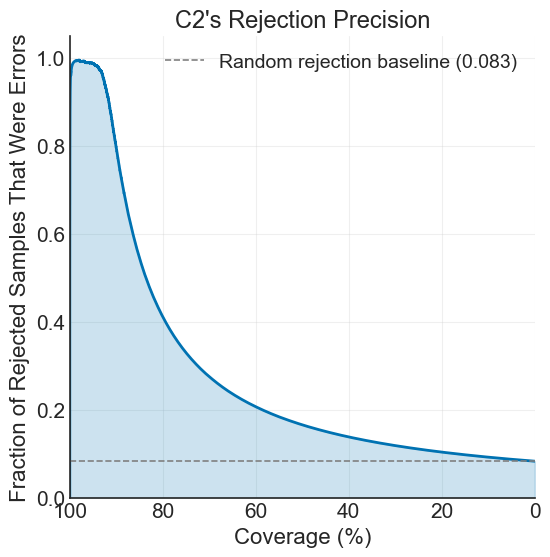

In [48]:
# Rejection Precision vs Coverage
# For each coverage level, what fraction of rejected samples were actually incorrect?

n = len(scores)
order = np.argsort(scores)[::-1]   # descending: most confident first
sorted_correct = correct[order]

coverages_pct = []
rejection_precision = []
rejection_precision_baseline = []

for k in range(1, n + 1):
    rejected = sorted_correct[k:]   # bottom (n-k) samples
    
    if len(rejected) == 0:
        continue  # nothing rejected at 100% coverage
    
    # fraction of rejected samples that were actually incorrect
    frac_errors_in_rejected = (1 - rejected).mean()
    
    coverages_pct.append(100 * k / n)
    rejection_precision.append(frac_errors_in_rejected)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(coverages_pct, rejection_precision, color='#0072B2', linewidth=2)
# fill
ax.fill_between(coverages_pct, rejection_precision, alpha=0.2, color='#0072B2')
ax.axhline(1 - correct.mean(), color='gray', linestyle='--', linewidth=1.2,
           label=f'Random rejection baseline ({1 - correct.mean():.3f})')
ax.set_xlabel('Coverage (%)')
ax.set_ylabel('Fraction of Rejected Samples That Were Errors')
ax.set_title(f'C2\'s Rejection Precision')
ax.set_xlim(100, 0)
ax.set_ylim(0, 1.05)
ax.legend()
plt.grid()
plt.show()

In [49]:
# Table with: threshold, coverage, FPR, FNR
# Threshold valeus to include: 0, 0.1, 0.2, ..., 0.9, 1
thresholds = np.arange(0, 1.01, 0.1)
table = []
for thr in thresholds:  
    accepted = qc_score >= thr
    
    # add the % of rejected sampels that were errors 
    if accepted.sum() == 0:
        coverage = 0
        fpr = np.nan
        fnr = np.nan
    else:
        yt = y_true[accepted]
        yp = y_pred[accepted]

        tn = np.sum((yt == 0) & (yp == 0))
        fp = np.sum((yt == 0) & (yp == 1))
        fn = np.sum((yt == 1) & (yp == 0))
        tp = np.sum((yt == 1) & (yp == 1))

        coverage = 100 * accepted.mean()
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan
        
        rejected_correct = correct[~accepted]
        rejection_precision = (1 - rejected_correct).mean() if (~accepted).sum() > 0 else np.nan

    table.append({
        'threshold': thr,
        'coverage': coverage,
        'FPR': fpr,
        'FNR': fnr,
        '% of Errors in Rejected': rejection_precision
    })
df_table = pd.DataFrame(table)
print(df_table)


    threshold    coverage       FPR       FNR  % of Errors in Rejected
0         0.0  100.000000  0.119251  0.071520                      NaN
1         0.1   92.009744  0.021086  0.006904                 0.919623
2         0.2   91.391872  0.015993  0.004561                 0.886030
3         0.3   90.940095  0.013000  0.003479                 0.857492
4         0.4   90.494962  0.010716  0.002829                 0.827353
5         0.5   90.078618  0.009155  0.002302                 0.799777
6         0.6   89.518326  0.007365  0.001899                 0.763364
7         0.7   88.858377  0.006333  0.001495                 0.722719
8         0.8   87.868453  0.004834  0.001218                 0.667945
9         0.9   85.948400  0.003842  0.000878                 0.579984
10        1.0    0.015502       NaN  0.000000                 0.082706


In [50]:
df_table

,threshold,coverage,FPR,FNR,% of Errors in Rejected
0,0.0,100.000000,0.119251,0.071520,NaN
1,0.1,92.009744,0.021086,0.006904,0.919623
2,0.2,91.391872,0.015993,0.004561,0.886030
3,0.3,90.940095,0.013000,0.003479,0.857492
4,0.4,90.494962,0.010716,0.002829,0.827353
5,0.5,90.078618,0.009155,0.002302,0.799777
6,0.6,89.518326,0.007365,0.001899,0.763364
7,0.7,88.858377,0.006333,0.001495,0.722719
8,0.8,87.868453,0.004834,0.001218,0.667945
9,0.9,85.948400,0.003842,0.000878,0.579984


In [51]:
# Wrap in print() so \n characters render as actual line breaks for Overleaf
# Clone the dataframe to avoid altering your working data
df_latex = df_table.copy()

# Replace underscores in column names and string columns
df_latex.columns = [col.replace('_', r'\_') for col in df_latex.columns]
for col in df_latex.select_dtypes(include=['object']).columns:
    df_latex[col] = df_latex[col].astype(str).str.replace('_', r'\_')

# Print the clean code
print(df_latex.to_latex(index=False))


\begin{tabular}{rrrrr}
\toprule
threshold & coverage & FPR & FNR & % of Errors in Rejected \\
\midrule
0.000000 & 100.000000 & 0.119251 & 0.071520 & NaN \\
0.100000 & 92.009744 & 0.021086 & 0.006904 & 0.919623 \\
0.200000 & 91.391872 & 0.015993 & 0.004561 & 0.886030 \\
0.300000 & 90.940095 & 0.013000 & 0.003479 & 0.857492 \\
0.400000 & 90.494962 & 0.010716 & 0.002829 & 0.827353 \\
0.500000 & 90.078618 & 0.009155 & 0.002302 & 0.799777 \\
0.600000 & 89.518326 & 0.007365 & 0.001899 & 0.763364 \\
0.700000 & 88.858377 & 0.006333 & 0.001495 & 0.722719 \\
0.800000 & 87.868453 & 0.004834 & 0.001218 & 0.667945 \\
0.900000 & 85.948400 & 0.003842 & 0.000878 & 0.579984 \\
1.000000 & 0.015502 & NaN & 0.000000 & 0.082706 \\
\bottomrule
\end{tabular}



: 